In [ ]:
# cell1 — Import libraries, mount Google Drive, and create permanent folders

import os
import json
import shutil
import zipfile
import time
import re
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/Skin_Disease_Project"
DATASET_DIR = os.path.join(PROJECT_DIR, "small_dataset")
ZIP_PATH = os.path.join(DATASET_DIR, "fitz_selected.zip")
EXTRACT_DIR = os.path.join(DATASET_DIR, "extracted")
SPLIT_DIR = os.path.join(DATASET_DIR, "split")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
APP_DIR = os.path.join(PROJECT_DIR, "app")

for folder in [DATASET_DIR, EXTRACT_DIR, MODEL_DIR, APP_DIR]:
    os.makedirs(folder, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
TensorFlow version: 2.21.0
Available GPUs: []
Project folder: /content/drive/MyDrive/Skin_Disease_Project


In [ ]:
# cell2 — Download the Fitz Selected dataset directly into Google Drive

import requests

DOWNLOAD_URL = (
    "https://zenodo.org/records/17470940/files/"
    "fitz_selected.zip?download=1"
)

# Reuse a plausible complete download. ZIP integrity is checked in cell3.
if os.path.isfile(ZIP_PATH) and os.path.getsize(ZIP_PATH) > 100_000_000:
    print("Existing ZIP found; will verify it in cell3.")
else:
    PART_PATH = ZIP_PATH + ".part"
    if os.path.exists(PART_PATH):
        os.remove(PART_PATH)

    print("Downloading Fitz Selected (~199 MB). Keep this cell running...")
    with requests.get(DOWNLOAD_URL, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()
        total = int(response.headers.get("content-length", 0))
        downloaded = 0

        with open(PART_PATH, "wb") as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)
                    downloaded += len(chunk)
                    if total:
                        print(
                            f"Downloaded {downloaded / 1e6:.1f} / "
                            f"{total / 1e6:.1f} MB",
                            end="\r"
                        )

    os.replace(PART_PATH, ZIP_PATH)
    print("\nDownload complete.")

print("ZIP size:", round(os.path.getsize(ZIP_PATH) / 1_000_000, 1), "MB")

Downloaded 198.9 / 198.9 MB
Download complete.
ZIP size: 198.9 MB


In [ ]:
# cell3 — Verify ZIP integrity and extract the dataset

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    if bad_file is not None:
        raise RuntimeError(f"ZIP integrity check failed at: {bad_file}")

    # Extract to a temporary folder first so a previous partial extraction is not mixed in.
    TEMP_EXTRACT_DIR = os.path.join(DATASET_DIR, "extracted_temp")
    if os.path.exists(TEMP_EXTRACT_DIR):
        shutil.rmtree(TEMP_EXTRACT_DIR)
    os.makedirs(TEMP_EXTRACT_DIR, exist_ok=True)
    archive.extractall(TEMP_EXTRACT_DIR)

# Replace the old extracted folder only after extraction succeeded.
if os.path.exists(EXTRACT_DIR):
    shutil.rmtree(EXTRACT_DIR)
os.rename(TEMP_EXTRACT_DIR, EXTRACT_DIR)

print("ZIP verified and extracted.")
print("Extracted path:", EXTRACT_DIR)
for root, dirs, files in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, "").count(os.sep)
    if level <= 2:
        print("  " * level + (os.path.basename(root) or "extracted") + "/")
        for filename in files[:4]:
            print("  " * (level + 1) + filename)

ZIP verified and extracted.
Extracted path: /content/drive/MyDrive/Skin_Disease_Project/small_dataset/extracted
extracted/
  fitz_selected/
    README.md
    ak/
      ac-ke_f0_101_b2e953bf.jpg
      ac-ke_f0_108_7571dac3.jpg
      ac-ke_f0_131_7063ed50.jpg
      ac-ke_f0_168_a95a1fdf.jpg
    bcc/
      ba-ce-ca-mo_f0_55_71b67be2.jpg
      ba-ce-ca-mo_f1_12_99aa6f56.jpg
      ba-ce-ca-mo_f1_16_1d5f5e2a.jpg
      ba-ce-ca-mo_f1_17_40727941.jpg
    bkl/
      se-de_f1_112_a78dbeda.jpg
      se-de_f1_114_863fe24b.jpg
      se-de_f1_1_e0f19367.jpg
      se-de_f1_20_22ab1ad4.jpg
    df/
      defi_f0_2_67ac5bba.jpg
      defi_f1_10_f64dc9f4.jpg
      defi_f1_11_54ed3d7d.jpg
      defi_f1_13_deb7f917.jpg
    mel/
      ma-me_f0_18_ee613356.jpg
      ma-me_f0_51_b6a30b0b.jpg
      ma-me_f0_63_0041c755.jpg
      ma-me_f0_71_9506d68f.jpg
    nv/
      co-ne_f0_31_beef6584.jpg
      co-ne_f1_10_8169683a.jpg
      co-ne_f1_18_58e9650f.jpg
      co-ne_f1_1_67a5980c.jpg
    scc/
      sq-ce-ca_f0_1

In [ ]:
# cell4 — Detect the image-class folder and count images in every class

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def direct_image_count(folder):
    return sum(
        1 for name in os.listdir(folder)
        if os.path.isfile(os.path.join(folder, name))
        and os.path.splitext(name)[1].lower() in IMAGE_EXTS
    )

candidates = []
for root, dirs, files in os.walk(EXTRACT_DIR):
    class_dirs_here = [
        os.path.join(root, name)
        for name in dirs
        if direct_image_count(os.path.join(root, name)) > 0
    ]
    if len(class_dirs_here) >= 2:
        total = sum(direct_image_count(d) for d in class_dirs_here)
        candidates.append((total, root, class_dirs_here))

if not candidates:
    raise RuntimeError(
        "Could not automatically find class folders. Review the folder listing "
        "from cell3 and share it so the folder path can be adjusted."
    )

_, IMAGE_ROOT, CLASS_DIRS = max(candidates, key=lambda item: item[0])

print("Detected image root:", IMAGE_ROOT)
print("\nImage count by class:")
total_images = 0
for folder in sorted(CLASS_DIRS):
    count = direct_image_count(folder)
    total_images += count
    print(f"{os.path.basename(folder)}: {count}")
print("\nTotal images:", total_images)
print("Detected classes:", len(CLASS_DIRS))

Detected image root: /content/drive/MyDrive/Skin_Disease_Project/small_dataset/extracted/fitz_selected

Image count by class:
ak: 358
bcc: 500
bkl: 195
df: 79
mel: 490
nv: 327
scc: 500

Total images: 2449
Detected classes: 7


In [ ]:
# cell5 — Install split-folders and split images into train/validation/test sets

%pip -q install split-folders

In [ ]:
# cell5 continued — Create a 70% / 15% / 15% split

import splitfolders

if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

splitfolders.ratio(
    IMAGE_ROOT,
    output=SPLIT_DIR,
    seed=42,
    ratio=(0.70, 0.15, 0.15),
    move=False
)

print("Dataset splitting completed.")
print("Output folders:", os.listdir(SPLIT_DIR))

Copying files: 2449 files [00:53, 46.10 files/s]

Dataset splitting completed.
Output folders: ['train', 'val', 'test']


In [ ]:
# cell6 — Load training, validation, and testing images

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "val"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

assert val_ds.class_names == class_names, "Validation class order differs."
assert test_ds.class_names == class_names, "Test class order differs."

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Disease categories:", class_names)
print("Number of classes:", NUM_CLASSES)
print("All datasets loaded successfully.")

Found 1712 files belonging to 7 classes.
Found 365 files belonging to 7 classes.
Found 372 files belonging to 7 classes.
Disease categories: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']
Number of classes: 7
All datasets loaded successfully.


In [ ]:
# cell8 — Calculate class weights to help with class imbalance

from sklearn.utils.class_weight import compute_class_weight

y_train = np.concatenate([labels.numpy() for images, labels in train_ds])
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=y_train
)
class_weights = {i: float(weight) for i, weight in enumerate(weights)}

print("Class weights:", class_weights)

Class weights: {0: 0.9782857142857143, 1: 0.6987755102040817, 2: 1.7983193277310925, 3: 4.4467532467532465, 4: 0.7130362349021241, 5: 1.0726817042606516, 6: 0.6987755102040817}


In [ ]:
# cell9 — Build the MobileNetV2 transfer-learning model

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.10)
], name="augmentation")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    augmentation,
    layers.Rescaling(1.0 / 127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.35),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="skin_lesion_mobilenetv2")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "skin_lesion_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# cell10 — Train with a persistent best-model checkpoint in Google Drive

BEST_PATH = os.path.join(MODEL_DIR, "best_skin_model.keras")

callbacks = [
    keras.callbacks.ModelCheckpoint(
        BEST_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=2,
        factor=0.2,
        min_lr=1e-7,
        verbose=1
    )
]

# If a checkpoint exists, load it rather than starting from random weights.
# This is a practical recovery point; it does not automatically resume the
# exact optimizer/epoch state of a previously interrupted fit().
if os.path.isfile(BEST_PATH):
    print("Existing best checkpoint found. Loading it.")
    model = keras.models.load_model(BEST_PATH)
else:
    print("No checkpoint found. Starting training.")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)

model = keras.models.load_model(BEST_PATH)
print("Training stage complete; best checkpoint loaded.")

No checkpoint found. Starting training.
Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 920ms/step - accuracy: 0.1839 - loss: 2.3644
Epoch 1: val_loss improved from None to 1.41679, saving model to /content/drive/MyDrive/Skin_Disease_Project/models/best_skin_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Skin_Disease_Project/models/best_skin_model.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - accuracy: 0.2325 - loss: 2.1748 - val_accuracy: 0.4658 - val_loss: 1.4168 - learning_rate: 0.0010
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 899ms/step - accuracy: 0.3683 - loss: 1.6595
Epoch 2: val_loss improved from 1.41679 to 1.34131, saving model to /content/drive/MyDrive/Skin_Disease_Project/models/best_skin_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Skin_Disease_Project/models/best_skin_model.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.3797 - loss: 1.6671 - val_accuracy: 0.5151 - val_loss: 1.3413 - learning_rate: 0.0010
Epoch 3/10
54/5

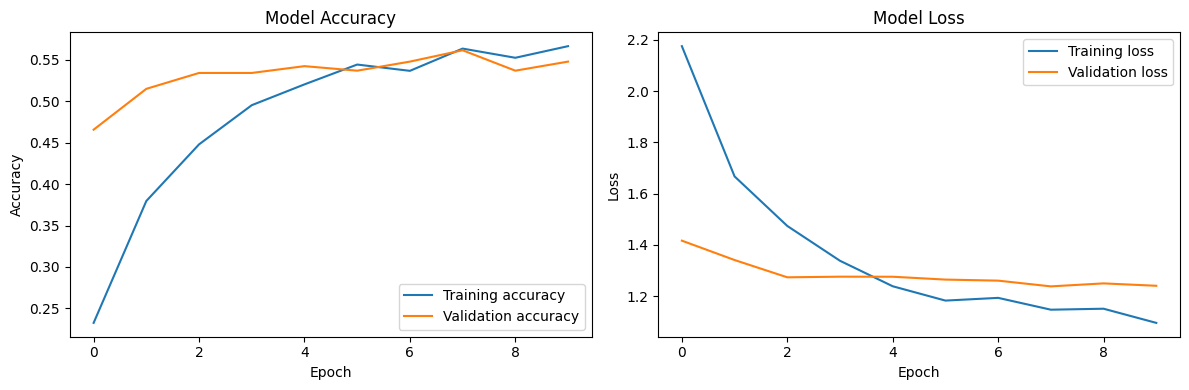

In [ ]:
# cell11 — Plot training and validation accuracy/loss

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history.get("accuracy", []), label="Training accuracy")
plt.plot(history.history.get("val_accuracy", []), label="Validation accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history.get("loss", []), label="Training loss")
plt.plot(history.history.get("val_loss", []), label="Validation loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# cell12 — Optional fine-tuning of the last MobileNetV2 layers

base_model = None
for layer in model.layers:
    if isinstance(layer, tf.keras.Model) and "mobilenetv2" in layer.name.lower():
        base_model = layer
        break

if base_model is None:
    print("Could not locate MobileNetV2 base inside the model. Skipping fine-tuning.")
else:
    base_model.trainable = True

    for layer in base_model.layers[:-30]:
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    fine_callbacks = [
        keras.callbacks.ModelCheckpoint(
            BEST_PATH, monitor="val_loss", save_best_only=True, verbose=1
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True, verbose=1
        )
    ]

    fine_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=5,
        class_weight=class_weights,
        callbacks=fine_callbacks
    )
    model = keras.models.load_model(BEST_PATH)
    print("Fine-tuning completed.")

Epoch 1/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5573 - loss: 1.1079
Epoch 1: val_loss improved from None to 1.23461, saving model to /content/drive/MyDrive/Skin_Disease_Project/models/best_skin_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Skin_Disease_Project/models/best_skin_model.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step - accuracy: 0.5654 - loss: 1.1048 - val_accuracy: 0.5370 - val_loss: 1.2346
Epoch 2/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5818 - loss: 1.0773
Epoch 2: val_loss improved from 1.23461 to 1.21584, saving model to /content/drive/MyDrive/Skin_Disease_Project/models/best_skin_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Skin_Disease_Project/models/best_skin_model.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - accuracy: 0.5888 - loss: 1.0730 - val_accuracy: 0.5397 - val_loss: 1.2158
Epoch 3/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6049 - loss: 1.0483
Epoch 3: val_loss did not imp

12/12 ━━━━━━━━━━━━━━━━━━━━ 13s 822ms/step - accuracy: 0.5538 - loss: 1.2730
Test Accuracy: 55.38%
Test Loss: 1.2730
12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 845ms/step

Classification Report:
              precision    recall  f1-score   support

          ak       0.67      0.51      0.58        55
         bcc       0.63      0.49      0.55        75
         bkl       0.27      0.60      0.37        30
          df       0.42      0.77      0.54        13
         mel       0.71      0.62      0.66        74
          nv       0.67      0.56      0.61        50
         scc       0.53      0.52      0.53        75

    accuracy                           0.55       372
   macro avg       0.56      0.58      0.55       372
weighted avg       0.60      0.55      0.57       372



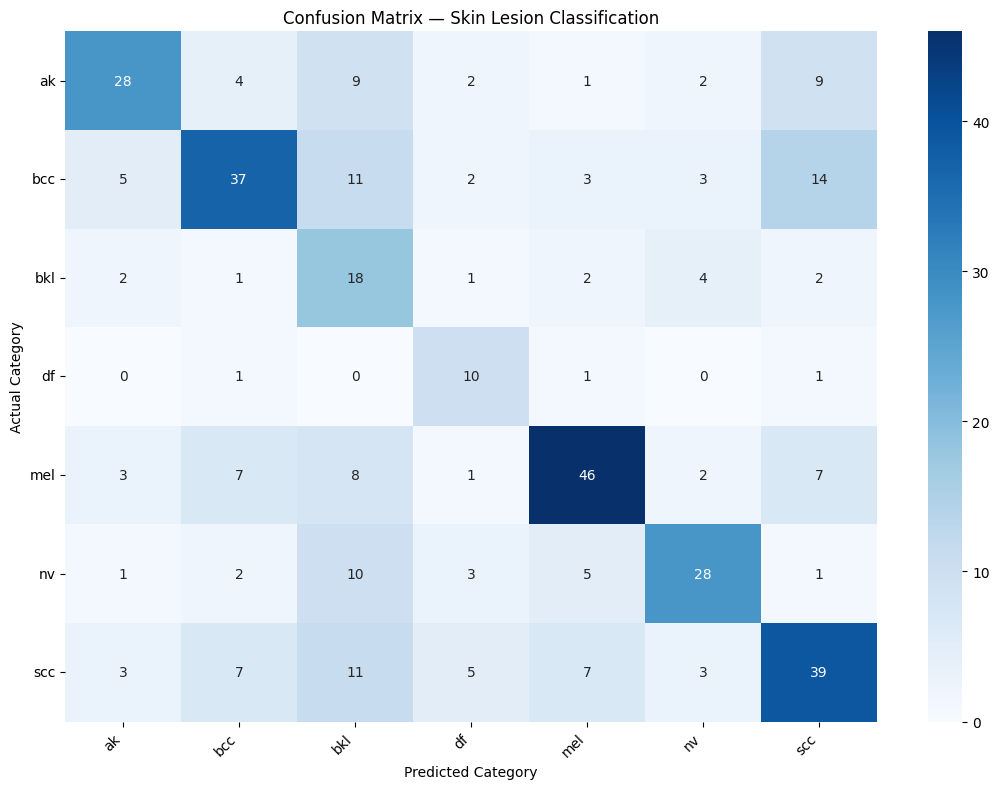

In [ ]:
# cell13 — Evaluate the final model on the held-out test set

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

y_true = np.concatenate([labels.numpy() for images, labels in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(11, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Confusion Matrix — Skin Lesion Classification")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# cell14 — Save the trained model in H5 and Keras formats plus class names

H5_PATH = os.path.join(MODEL_DIR, "skin_disease_model.h5")
KERAS_PATH = os.path.join(MODEL_DIR, "skin_disease_model.keras")
CLASSES_PATH = os.path.join(MODEL_DIR, "class_names.json")

# Save to Google Drive so files remain after a Colab runtime disconnects.
model.save(H5_PATH)
model.save(KERAS_PATH)

with open(CLASSES_PATH, "w", encoding="utf-8") as file:
    json.dump(class_names, file, indent=2)

print("Model and labels saved:")
for path in [BEST_PATH, H5_PATH, KERAS_PATH, CLASSES_PATH]:
    print(path, "| exists:", os.path.isfile(path))

Model and labels saved:
/content/drive/MyDrive/Skin_Disease_Project/models/best_skin_model.keras | exists: True
/content/drive/MyDrive/Skin_Disease_Project/models/skin_disease_model.h5 | exists: True
/content/drive/MyDrive/Skin_Disease_Project/models/skin_disease_model.keras | exists: True
/content/drive/MyDrive/Skin_Disease_Project/models/class_names.json | exists: True


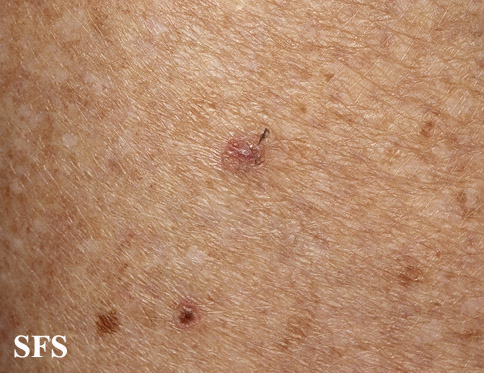

Predicted class: ak
Model score: 72.49%


In [ ]:
# cell15 — Test prediction on one test image using the saved model

saved_model = keras.models.load_model(H5_PATH)

example_image_path = None
for class_name in class_names:
    folder = os.path.join(SPLIT_DIR, "test", class_name)
    if os.path.isdir(folder):
        matches = [
            name for name in os.listdir(folder)
            if os.path.splitext(name)[1].lower() in IMAGE_EXTS
        ]
        if matches:
            example_image_path = os.path.join(folder, matches[0])
            break

if example_image_path:
    image = Image.open(example_image_path).convert("RGB")
    display(image)
    resized = image.resize(IMG_SIZE)
    arr = np.asarray(resized, dtype=np.float32)[None, ...]
    scores = saved_model.predict(arr, verbose=0)[0]
    index = int(np.argmax(scores))
    print("Predicted class:", class_names[index])
    print(f"Model score: {scores[index] * 100:.2f}%")
else:
    print("No test image was found.")

In [ ]:
# cell16 — Create Streamlit app with full medical disease names

APP_PATH = os.path.join(APP_DIR, "app.py")

app_code = r'''
import os
import json
import re
import numpy as np
import streamlit as st
from PIL import Image
from tensorflow import keras

st.set_page_config(
    page_title="Skin Disease Classification",
    page_icon="🔬",
    layout="centered"
)

st.title("🔬 Skin Disease Classification")
st.write("Upload a skin image to see the predicted category.")

PROJECT_DIR = "/content/drive/MyDrive/Skin_Disease_Project"
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
KERAS_PATH = os.path.join(MODEL_DIR, "skin_disease_model.keras")
H5_PATH = os.path.join(MODEL_DIR, "skin_disease_model.h5")
CLASSES_PATH = os.path.join(MODEL_DIR, "class_names.json")

# Map recognized dataset labels to full medical names.
MEDICAL_NAMES = {
    "ak": "Actinic Keratosis",
    "akiec": "Actinic Keratoses and Intraepithelial Carcinoma",
    "bcc": "Basal Cell Carcinoma",
    "bkl": "Benign Keratosis-Like Lesion",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic Nevus (Mole)",
    "scc": "Squamous Cell Carcinoma",
    "vasc": "Vascular Lesion",
    "sek": "Seborrheic Keratosis",
    "sk": "Seborrheic Keratosis",
    "lentigo": "Lentigo",
    "acne": "Acne",
    "rosacea": "Rosacea",
    "eczema": "Eczema (Dermatitis)"
}

def get_medical_name(label):
    # Normalize labels such as "AK", "ak", or "A-K".
    key = re.sub(r"[^a-z0-9]", "", str(label).lower())

    if key in MEDICAL_NAMES:
        return MEDICAL_NAMES[key]

    # Preserve descriptive class names if they already exist.
    cleaned = str(label).replace("_", " ").replace("-", " ").strip()

    # Never invent a medical name for an unknown abbreviation.
    if len(cleaned) <= 8 and " " not in cleaned:
        return f"Full medical name not verified for label: {cleaned}"

    return cleaned.title()


@st.cache_resource
def load_saved_model():
    if os.path.exists(KERAS_PATH):
        model_path = KERAS_PATH
    elif os.path.exists(H5_PATH):
        model_path = H5_PATH
    else:
        raise FileNotFoundError("No saved model was found in Google Drive.")

    model = keras.models.load_model(model_path)

    with open(CLASSES_PATH, "r", encoding="utf-8") as file:
        class_names = json.load(file)

    return model, class_names


try:
    model, class_names = load_saved_model()
    st.success("Trained model loaded successfully.")
except Exception as error:
    st.error(f"Could not load the model: {error}")
    st.stop()


uploaded_file = st.file_uploader(
    "Upload a skin image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    try:
        image = Image.open(uploaded_file).convert("RGB")

        st.image(
            image,
            caption="Uploaded Skin Image",
            use_container_width=True
        )

        if st.button("Predict Disease", type="primary"):
            # Use the same image size as training.
            resized_image = image.resize((160, 160))

            image_array = np.asarray(
                resized_image, dtype=np.float32
            )
            image_array = np.expand_dims(image_array, axis=0)

            # Predict the class.
            predictions = model.predict(image_array, verbose=0)[0]

            if len(predictions) != len(class_names):
                st.error("Model output does not match the class names.")
                st.stop()

            predicted_index = int(np.argmax(predictions))
            original_label = class_names[predicted_index]
            medical_name = get_medical_name(original_label)
            confidence = float(predictions[predicted_index])

            st.subheader("Prediction Result")

            # Display the full medical name prominently.
            st.success(f"Predicted Medical Name: {medical_name}")

            # Keep the original dataset label for reference.
            st.write(f"Dataset Label: {original_label}")
            st.write(f"Model Score: {confidence * 100:.2f}%")
            st.progress(confidence)

            if medical_name.startswith(
                "Full medical name not verified"
            ):
                st.warning(
                    "This abbreviation needs to be checked against "
                    "the dataset documentation before assigning a "
                    "full medical name."
                )

            if confidence < 0.60:
                st.warning(
                    "The model is uncertain. The prediction may be incorrect."
                )

            # Display the top three predictions.
            st.subheader("Top 3 Predictions")

            top_indices = np.argsort(predictions)[::-1][:3]

            for index in top_indices:
                label = class_names[int(index)]
                full_name = get_medical_name(label)
                score = float(predictions[int(index)]) * 100

                st.write(
                    f"**{full_name}** — {score:.2f}%"
                )

    except Exception as error:
        st.error(f"Could not process the image: {error}")


st.warning(
    "Educational use only. This application is not a medical "
    "diagnostic tool. Predictions may be incorrect. Consult a "
    "qualified healthcare professional for medical concerns."
)
'''

with open(APP_PATH, "w", encoding="utf-8") as file:
    file.write(app_code)

print("Streamlit app updated:", APP_PATH)

Streamlit app updated: /content/drive/MyDrive/Skin_Disease_Project/app/app.py


In [ ]:
# cell17 — Install Streamlit

%pip -q install streamlit

In [ ]:
# cell18 — Download Cloudflare Tunnel

CLOUDFLARED_PATH = "/content/cloudflared"

if not os.path.isfile(CLOUDFLARED_PATH):
    subprocess.run(
        [
            "wget", "-q",
            "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
            "-O", CLOUDFLARED_PATH
        ],
        check=True
    )

os.chmod(CLOUDFLARED_PATH, 0o755)
version_result = subprocess.run(
    [CLOUDFLARED_PATH, "--version"],
    capture_output=True, text=True, check=True
)
print("Cloudflare Tunnel:", version_result.stdout.strip())

Cloudflare Tunnel: cloudflared version 2026.10.3 (built 2026-10-21-13:11 UTC)


In [ ]:
# cell19 — Start Streamlit and verify that the server is healthy

APP_LOG = "/content/streamlit_app.log"

# Stop an older process launched from this notebook if it is still running.
try:
    if "streamlit_process" in globals() and streamlit_process.poll() is None:
        streamlit_process.terminate()
        streamlit_process.wait(timeout=10)
except Exception:
    pass

log_handle = open(APP_LOG, "w")
streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", APP_PATH,
        "--server.port", "8501",
        "--server.address", "127.0.0.1",
        "--server.headless", "true"
    ],
    stdout=log_handle,
    stderr=subprocess.STDOUT
)

import urllib.request
server_ready = False

for _ in range(30):
    if streamlit_process.poll() is not None:
        break
    try:
        with urllib.request.urlopen(
            "http://127.0.0.1:8501/_stcore/health", timeout=2
        ) as response:
            if response.status == 200:
                server_ready = True
                break
    except Exception:
        time.sleep(2)

if server_ready:
    print("Streamlit server is running on port 8501.")
else:
    with open(APP_LOG, "r") as f:
        print(f.read()[-5000:])
    raise RuntimeError("Streamlit did not start. Check the log above.")

Streamlit server is running on port 8501.


In [ ]:
# cell20 — Start a temporary public tunnel and print the website URL

TUNNEL_LOG = "/content/cloudflared.log"

try:
    if "tunnel_process" in globals() and tunnel_process.poll() is None:
        tunnel_process.terminate()
        tunnel_process.wait(timeout=10)
except Exception:
    pass

tunnel_handle = open(TUNNEL_LOG, "w")
tunnel_process = subprocess.Popen(
    [
        CLOUDFLARED_PATH,
        "tunnel",
        "--url", "http://127.0.0.1:8501",
        "--no-autoupdate"
    ],
    stdout=tunnel_handle,
    stderr=subprocess.STDOUT
)

public_url = None
for _ in range(60):
    if tunnel_process.poll() is not None:
        break
    time.sleep(2)
    try:
        with open(TUNNEL_LOG, "r") as f:
            log_text = f.read()
        matches = re.findall(
            r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
            log_text
        )
        if matches:
            public_url = matches[0]
            break
    except Exception:
        pass

if public_url:
    print("Your temporary Streamlit website URL:")
    print(public_url)
else:
    with open(TUNNEL_LOG, "r") as f:
        print(f.read()[-5000:])
    print("Tunnel URL not found. Check the log above.")

Your temporary Streamlit website URL:
https://enclosed-techniques-underwear-husband.trycloudflare.com
